In [ ]:
import pandas as pd
import numpy as np

# 1. Caricamento
df = pd.read_csv("entsoe_data_processed_v2.1.csv")
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)

print(f"Shape iniziale: {df.shape}")
print(f"Zone: {df['country'].nunique()}")

# 2. Filtro qualità
n_prima = len(df)
righe_bad = df["qualita_ok"] == False
print(f"\nRighe qualita_ok=False: {righe_bad.sum()}")
print("Per paese:")
print(df.loc[righe_bad, "country"].value_counts().to_string())

df = df[df["qualita_ok"]].drop(columns="qualita_ok").reset_index(drop=True)
print(f"\nRimosse {n_prima - len(df)} righe. Shape dopo filtro: {df.shape}")
print(f"Zone rimaste: {df['country'].nunique()}")

# 3. Feature temporali + target
df["ora"] = df["datetime"].dt.hour
df["giorno_settimana"] = df["datetime"].dt.day_of_week
df["mese"] = df["datetime"].dt.month
df["target_T1"] = (df["price"] <= 0).astype(int)

# 4. Flag train/test
split_ts = pd.Timestamp("2025-01-01", tz="UTC")
df["is_train"] = (df["datetime"] < split_ts).to_numpy()

print(f"\nTrain: {df['is_train'].sum()} | Test: {(~df['is_train']).sum()}")
print(f"Target=1 train: {df.loc[df['is_train'], 'target_T1'].mean():.2%} | "
      f"test: {df.loc[~df['is_train'], 'target_T1'].mean():.2%}")

Shape iniziale: (288288, 14)
Zone: 22

Righe qualita_ok=False: 4992
Per paese:
country
CH         4320
IT_NORD     672

Rimosse 4992 righe. Shape dopo filtro: (283296, 13)
Zone rimaste: 22

Train: 193269 | Test: 90027
Target=1 train: 4.24% | test: 6.25%


In [5]:
# ── 1. Definizione delle features (produzione + ora + giorno + zona) ──
colonne_produzione = [
    "nuclear", "fossil_gas", "solar", "waste", "wind_offshore",
    "wind_onshore", "biomass", "fossil_brown_coal_lignite",
    "fossil_hard_coal", "hydro_total",
]
features = colonne_produzione + ["ora", "giorno_settimana", "country"]

X = df[features].copy()
y = df["target_T1"].copy()

# ── 2. One-Hot Encoding per la variabile geografica ──
X = pd.get_dummies(X, columns=["country"], drop_first=True, dtype=int)

# ── 3. Split TEMPORALE (corretto) ──
# Sostituisce train_test_split random: niente mescolamento tra passato e futuro.
split_ts = pd.Timestamp("2025-01-01", tz="UTC")
mask_train = (df["datetime"] < split_ts).to_numpy()
mask_test  = ~mask_train

X_train, y_train = X[mask_train], y[mask_train]
X_test,  y_test  = X[mask_test],  y[mask_test]

# Allineamento colonne (nel caso una zona sparisca dal test)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# ── 4. Controlli anti-leakage ──
assert df.loc[mask_train, "datetime"].max() < df.loc[mask_test, "datetime"].min()
assert "price" not in X.columns
assert "target_T1" not in X.columns
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()

# ── 5. Riepilogo ──
print("--- Dati X e y pronti per l'addestramento (SPLIT TEMPORALE) ---")
print(f"Train: {X_train.shape[0]} righe, {X_train.shape[1]} colonne  "
      f"({df.loc[mask_train, 'datetime'].min()} → {df.loc[mask_train, 'datetime'].max()})")
print(f"Test : {X_test.shape[0]} righe, {X_test.shape[1]} colonne  "
      f"({df.loc[mask_test, 'datetime'].min()} → {df.loc[mask_test, 'datetime'].max()})")
print(f"Percentuale target=1 nel Train: {y_train.mean():.2%}")
print(f"Percentuale target=1 nel Test : {y_test.mean():.2%}")

--- Dati X e y pronti per l'addestramento (SPLIT TEMPORALE) ---
Train: 193269 righe, 33 colonne  (2023-12-31 23:00:00+00:00 → 2024-12-31 23:00:00+00:00)
Test : 90027 righe, 33 colonne  (2025-01-01 00:00:00+00:00 → 2025-06-29 22:00:00+00:00)
Percentuale target=1 nel Train: 4.24%
Percentuale target=1 nel Test : 6.25%


Addestramento del Random Forest in corso...

--- REPORT DI CLASSIFICAZIONE (TASK 1) ---
              precision    recall  f1-score   support

  Prezzo > 0       0.96      0.99      0.97     84396
 Prezzo <= 0       0.69      0.39      0.50      5631

    accuracy                           0.95     90027
   macro avg       0.83      0.69      0.74     90027
weighted avg       0.94      0.95      0.94     90027



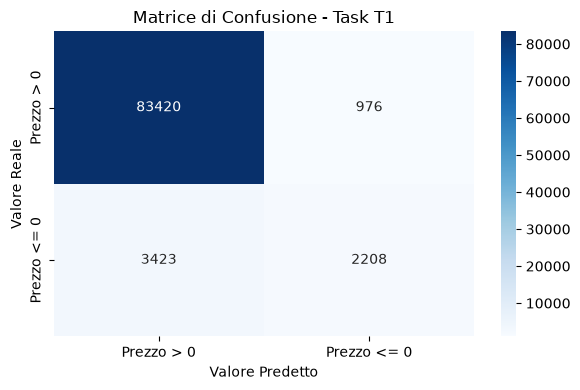

/var/folders/cq/1g6r7fvn2v17_75jqzn2479c0000gn/T/ipykernel_60102/4235332158.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette="viridis")


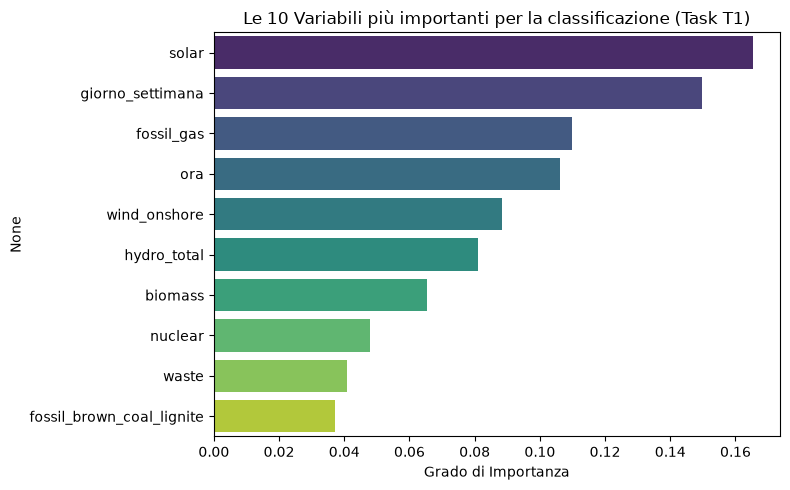


✅ File salvati in: /Users/antonio/Desktop/Classificazione/output/random_forest


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# ── Cartella di output ──
out_dir = Path("output/random_forest")
out_dir.mkdir(parents=True, exist_ok=True)

# 1. Inizializzazione e Addestramento del Modello
print("Addestramento del Random Forest in corso...")
rf_model_t1 = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
rf_model_t1.fit(X_train, y_train)

# 2. Previsione sui dati di Test
y_pred = rf_model_t1.predict(X_test)

# 3. Report delle Metriche — stampa + salva su file
report_str = classification_report(
    y_test, y_pred, target_names=["Prezzo > 0", "Prezzo <= 0"]
)
print("\n--- REPORT DI CLASSIFICAZIONE (TASK 1) ---")
print(report_str)

(out_dir / "classification_report_t1.txt").write_text(report_str, encoding="utf-8")

# 4. Matrice di Confusione — salva in out_dir
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prezzo > 0', 'Prezzo <= 0'],
            yticklabels=['Prezzo > 0', 'Prezzo <= 0'])
plt.title("Matrice di Confusione - Task T1")
plt.ylabel('Valore Reale')
plt.xlabel('Valore Predetto')
plt.tight_layout()
plt.savefig(out_dir / "matrice_confusione_t1.png", dpi=300)
plt.show()

# 5. Feature Importance — salva in out_dir
importances = (
    pd.Series(rf_model_t1.feature_importances_, index=X_train.columns)
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Le 10 Variabili più importanti per la classificazione (Task T1)")
plt.xlabel("Grado di Importanza")
plt.tight_layout()
plt.savefig(out_dir / "feature_importance_t1.png", dpi=300)
plt.show()

print(f"\n✅ File salvati in: {out_dir.resolve()}")

1. Standardizzazione (fit su train, transform su test)...
2. Addestramento KNN (fit istantaneo)...
3. Predizione su 90k righe (può richiedere 5-20 minuti)...
   Predizione completata in 18s

=== KNN (k=5) (soglia 0.5) ===
              precision    recall  f1-score   support

  Prezzo > 0       0.96      0.99      0.97     84396
 Prezzo <= 0       0.65      0.39      0.49      5631

    accuracy                           0.95     90027
   macro avg       0.81      0.69      0.73     90027
weighted avg       0.94      0.95      0.94     90027

{'accuracy': 0.9491, 'precision': 0.6541, 'recall': 0.395, 'f1': 0.4925, 'roc_auc': 0.8266, 'pr_auc': 0.4378}


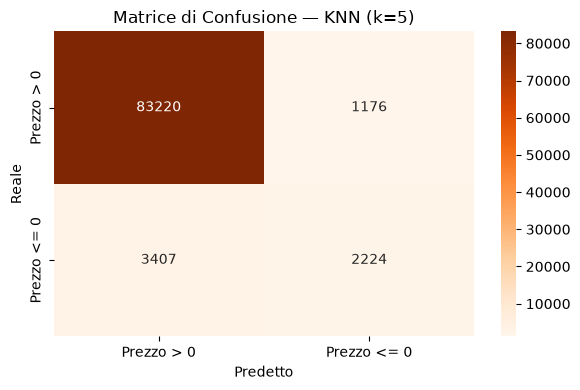


=== Riepilogo ===
           accuracy  precision  recall      f1  roc_auc  pr_auc
KNN (k=5)    0.9491     0.6541   0.395  0.4925   0.8266  0.4378

✅ File salvati in: /Users/antonio/Desktop/Classificazione/output/knn


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
)
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import time

# ══════════════════════════════════════════════════════════════
# Helper + accumulatori (se già esistono, li preserva)
# ══════════════════════════════════════════════════════════════
try:
    risultati
except NameError:
    risultati = {}
try:
    y_proba_dict
except NameError:
    y_proba_dict = {}


def valuta_modello(nome, modello, X_te, y_te, soglia=0.5):
    y_proba = modello.predict_proba(X_te)[:, 1]
    y_pred  = (y_proba >= soglia).astype(int)
    met = {
        "accuracy":  accuracy_score(y_te, y_pred),
        "precision": precision_score(y_te, y_pred, zero_division=0),
        "recall":    recall_score(y_te, y_pred, zero_division=0),
        "f1":        f1_score(y_te, y_pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_te, y_proba),
        "pr_auc":    average_precision_score(y_te, y_proba),
    }
    risultati[nome]    = met
    y_proba_dict[nome] = y_proba
    print(f"\n=== {nome} (soglia {soglia}) ===")
    print(classification_report(y_te, y_pred, target_names=["Prezzo > 0", "Prezzo <= 0"]))
    print({k: round(v, 4) for k, v in met.items()})
    return y_pred


# ══════════════════════════════════════════════════════════════
# Cartella di output
# ══════════════════════════════════════════════════════════════
out_dir = Path("output/knn")
out_dir.mkdir(parents=True, exist_ok=True)

# ══════════════════════════════════════════════════════════════
# 1. Standardizzazione
# ══════════════════════════════════════════════════════════════
print("1. Standardizzazione (fit su train, transform su test)...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ══════════════════════════════════════════════════════════════
# 2. KNN
# ══════════════════════════════════════════════════════════════
print("2. Addestramento KNN (fit istantaneo)...")
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_scaled, y_train)

print("3. Predizione su 90k righe (può richiedere 5-20 minuti)...")
t0 = time.time()
y_proba_knn = knn.predict_proba(X_test_scaled)[:, 1]
print(f"   Predizione completata in {time.time() - t0:.0f}s")

# ══════════════════════════════════════════════════════════════
# 3. Valutazione
# ══════════════════════════════════════════════════════════════
y_pred_knn = (y_proba_knn >= 0.5).astype(int)

met = {
    "accuracy":  accuracy_score(y_test, y_pred_knn),
    "precision": precision_score(y_test, y_pred_knn, zero_division=0),
    "recall":    recall_score(y_test, y_pred_knn, zero_division=0),
    "f1":        f1_score(y_test, y_pred_knn, zero_division=0),
    "roc_auc":   roc_auc_score(y_test, y_proba_knn),
    "pr_auc":    average_precision_score(y_test, y_proba_knn),
}
risultati["KNN (k=5)"]    = met
y_proba_dict["KNN (k=5)"] = y_proba_knn

print("\n=== KNN (k=5) (soglia 0.5) ===")
report_str = classification_report(
    y_test, y_pred_knn, target_names=["Prezzo > 0", "Prezzo <= 0"]
)
print(report_str)
print({k: round(v, 4) for k, v in met.items()})

(out_dir / "classification_report_t1.txt").write_text(report_str, encoding="utf-8")

# ══════════════════════════════════════════════════════════════
# 4. Matrice di confusione
# ══════════════════════════════════════════════════════════════
plt.figure(figsize=(6, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_knn),
    annot=True, fmt="d", cmap="Oranges",
    xticklabels=["Prezzo > 0", "Prezzo <= 0"],
    yticklabels=["Prezzo > 0", "Prezzo <= 0"],
)
plt.title("Matrice di Confusione — KNN (k=5)")
plt.ylabel("Reale")
plt.xlabel("Predetto")
plt.tight_layout()
plt.savefig(out_dir / "matrice_confusione_knn_t1.png", dpi=300)
plt.show()

# ══════════════════════════════════════════════════════════════
# 5. Riepilogo
# ══════════════════════════════════════════════════════════════
print("\n=== Riepilogo ===")
print(pd.DataFrame(risultati).T.round(4).to_string())
print(f"\n✅ File salvati in: {out_dir.resolve()}")

1. Addestramento Decision Tree...
   Fit completato in 1.9s

=== Decision Tree (soglia 0.5) ===
              precision    recall  f1-score   support

  Prezzo > 0       0.97      0.94      0.96     84396
 Prezzo <= 0       0.42      0.62      0.50      5631

    accuracy                           0.92     90027
   macro avg       0.70      0.78      0.73     90027
weighted avg       0.94      0.92      0.93     90027

{'accuracy': 0.9236, 'precision': 0.4239, 'recall': 0.6152, 'f1': 0.502, 'roc_auc': 0.7856, 'pr_auc': 0.2923}


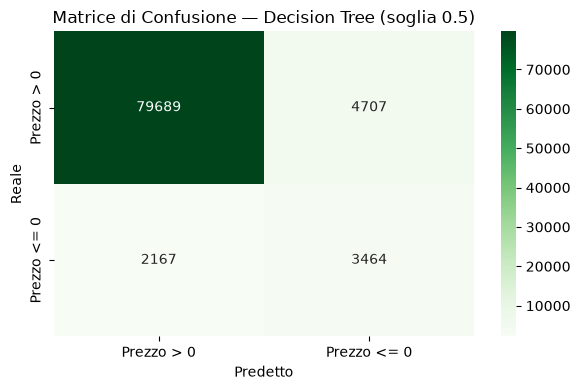

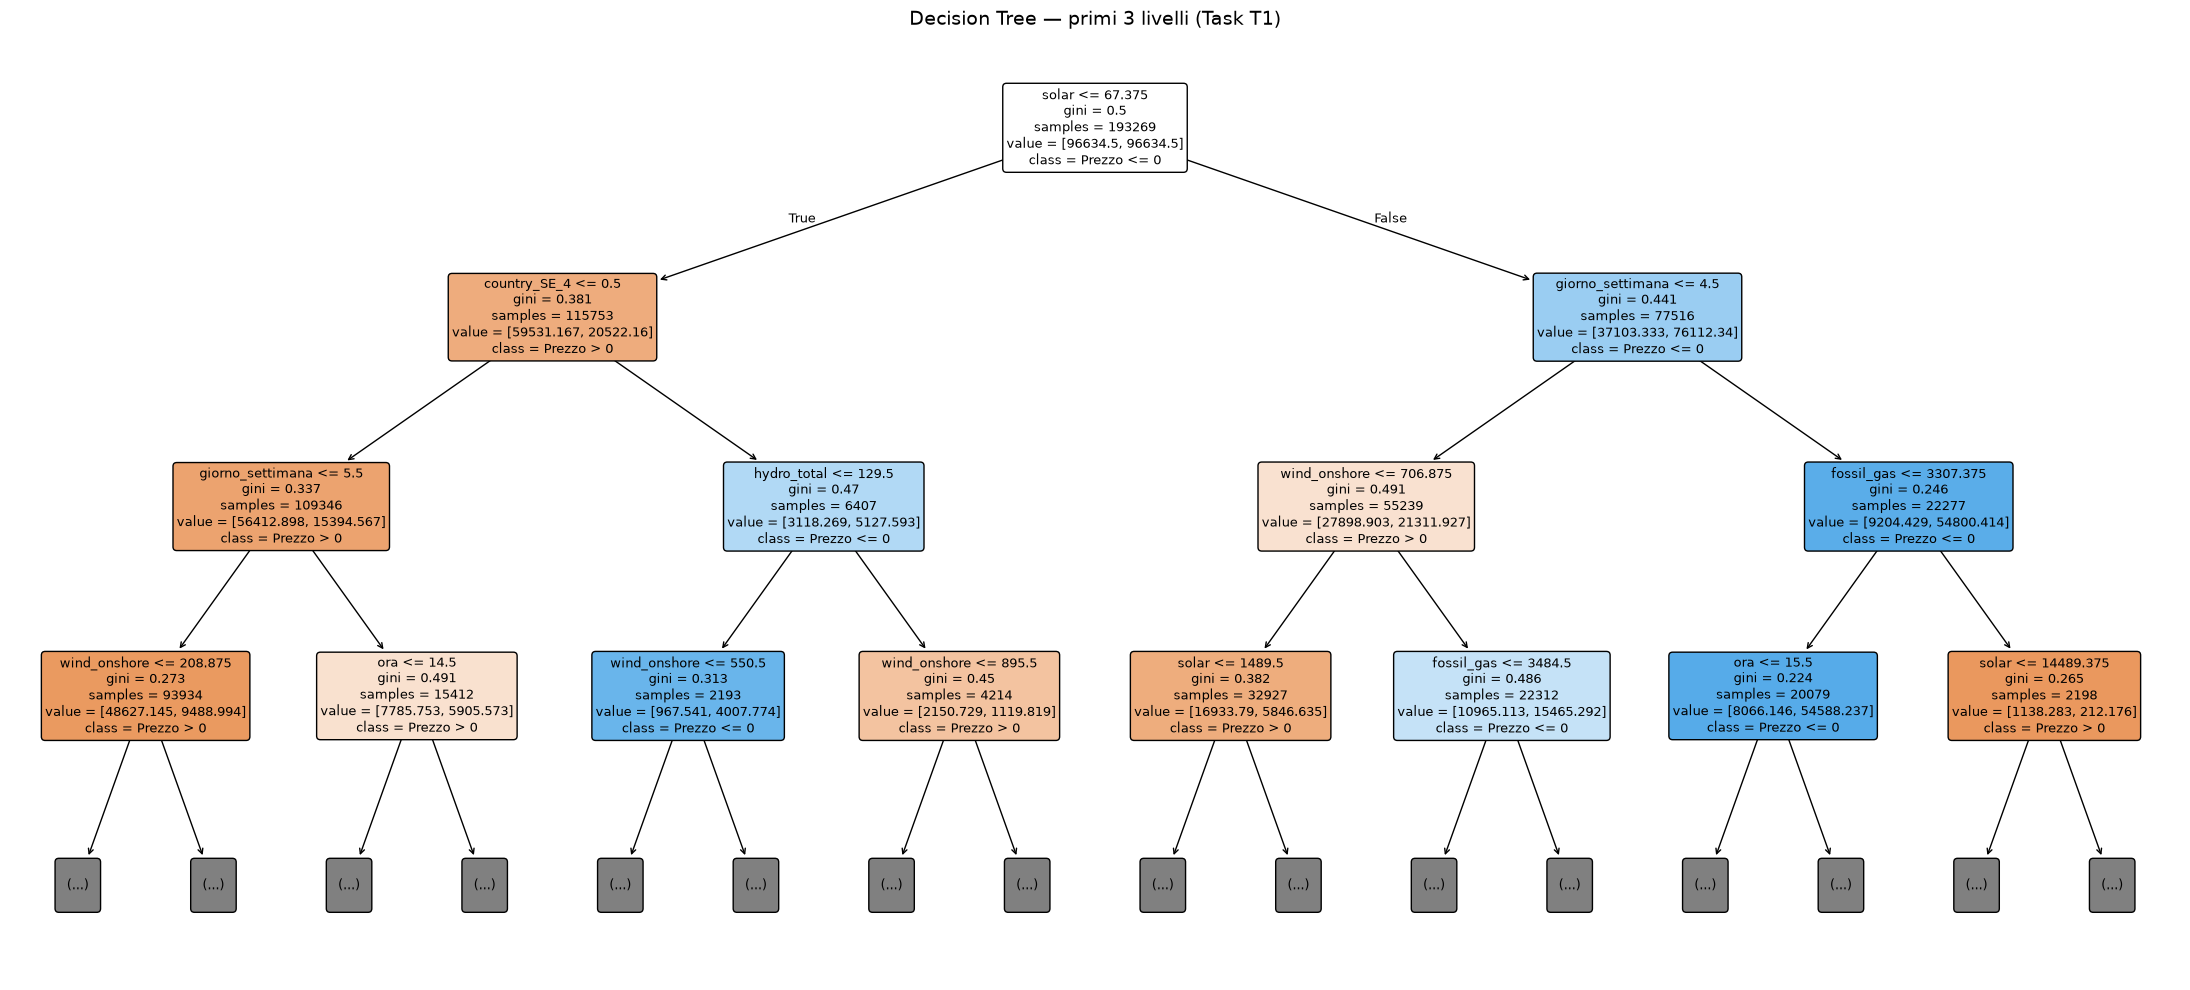


=== Riepilogo ===
               accuracy  precision  recall      f1  roc_auc  pr_auc
KNN (k=5)        0.9491     0.6541  0.3950  0.4925   0.8266  0.4378
Decision Tree    0.9236     0.4239  0.6152  0.5020   0.7856  0.2923

✅ File salvati in: /Users/antonio/Desktop/Classificazione/output/decision_tree


In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
)
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import time

# ── Helper + accumulatori (idempotenti) ──
try:
    risultati
except NameError:
    risultati = {}
try:
    y_proba_dict
except NameError:
    y_proba_dict = {}


def valuta_modello(nome, modello, X_te, y_te, soglia=0.5):
    y_proba = modello.predict_proba(X_te)[:, 1]
    y_pred  = (y_proba >= soglia).astype(int)
    met = {
        "accuracy":  accuracy_score(y_te, y_pred),
        "precision": precision_score(y_te, y_pred, zero_division=0),
        "recall":    recall_score(y_te, y_pred, zero_division=0),
        "f1":        f1_score(y_te, y_pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_te, y_proba),
        "pr_auc":    average_precision_score(y_te, y_proba),
    }
    risultati[nome]    = met
    y_proba_dict[nome] = y_proba
    print(f"\n=== {nome} (soglia {soglia}) ===")
    print(classification_report(y_te, y_pred, target_names=["Prezzo > 0", "Prezzo <= 0"]))
    print({k: round(v, 4) for k, v in met.items()})
    return y_pred


# ── Cartella di output ──
out_dir = Path("output/decision_tree")
out_dir.mkdir(parents=True, exist_ok=True)

# ══════════════════════════════════════════════════════════════
# 1. Decision Tree
# ══════════════════════════════════════════════════════════════
print("1. Addestramento Decision Tree...")
t0 = time.time()
dt = DecisionTreeClassifier(
    max_depth=20,
    class_weight="balanced",
    random_state=42,
)
dt.fit(X_train, y_train)
print(f"   Fit completato in {time.time() - t0:.1f}s")

y_pred_dt = valuta_modello("Decision Tree", dt, X_test, y_test)

# ── Salvataggio report testuale ──
report_str = classification_report(
    y_test, y_pred_dt, target_names=["Prezzo > 0", "Prezzo <= 0"]
)
(out_dir / "classification_report_t1.txt").write_text(report_str, encoding="utf-8")

# ── Matrice di confusione ──
plt.figure(figsize=(6, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_dt),
    annot=True, fmt="d", cmap="Greens",
    xticklabels=["Prezzo > 0", "Prezzo <= 0"],
    yticklabels=["Prezzo > 0", "Prezzo <= 0"],
)
plt.title("Matrice di Confusione — Decision Tree (soglia 0.5)")
plt.ylabel("Reale")
plt.xlabel("Predetto")
plt.tight_layout()
plt.savefig(out_dir / "matrice_confusione_dt_t1.png", dpi=300)
plt.show()

# ══════════════════════════════════════════════════════════════
# 2. Struttura dell'albero (primi 3 livelli)
# ══════════════════════════════════════════════════════════════
plt.figure(figsize=(22, 10))
plot_tree(
    dt, max_depth=3,
    feature_names=X_train.columns,
    class_names=["Prezzo > 0", "Prezzo <= 0"],
    filled=True, proportion=False, fontsize=9, rounded=True,
)
plt.title("Decision Tree — primi 3 livelli (Task T1)", fontsize=14)
plt.tight_layout()
plt.savefig(out_dir / "struttura_albero_dt_t1.png", dpi=300)
plt.show()

# ══════════════════════════════════════════════════════════════
# 3. Riepilogo
# ══════════════════════════════════════════════════════════════
print("\n=== Riepilogo ===")
print(pd.DataFrame(risultati).T.round(4).to_string())
print(f"\n✅ File salvati in: {out_dir.resolve()}")

1. Addestramento GaussianNB...
   Fit completato in 0.1s

=== Naive Bayes (soglia 0.5) ===
              precision    recall  f1-score   support

  Prezzo > 0       0.96      0.96      0.96     84396
 Prezzo <= 0       0.37      0.36      0.36      5631

    accuracy                           0.92     90027
   macro avg       0.67      0.66      0.66     90027
weighted avg       0.92      0.92      0.92     90027

{'accuracy': 0.9223, 'precision': 0.3731, 'recall': 0.3561, 'f1': 0.3644, 'roc_auc': 0.8444, 'pr_auc': 0.321}


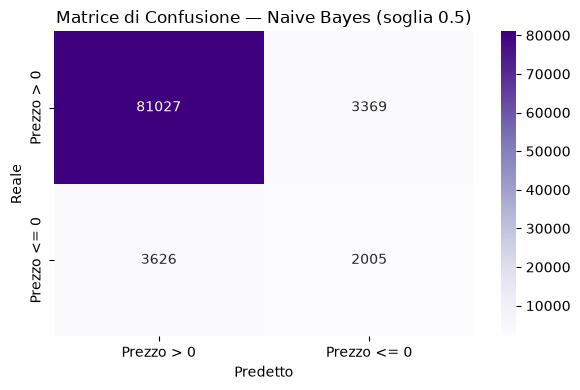


=== Riepilogo ===
               accuracy  precision  recall      f1  roc_auc  pr_auc
KNN (k=5)        0.9491     0.6541  0.3950  0.4925   0.8266  0.4378
Decision Tree    0.9236     0.4239  0.6152  0.5020   0.7856  0.2923
Naive Bayes      0.9223     0.3731  0.3561  0.3644   0.8444  0.3210

✅ File salvati in: /Users/antonio/Desktop/Classificazione/output/naive_bayes


In [9]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
)
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import time

# ── Helper + accumulatori (idempotenti) ──
try:
    risultati
except NameError:
    risultati = {}
try:
    y_proba_dict
except NameError:
    y_proba_dict = {}


def valuta_modello(nome, modello, X_te, y_te, soglia=0.5):
    y_proba = modello.predict_proba(X_te)[:, 1]
    y_pred  = (y_proba >= soglia).astype(int)
    met = {
        "accuracy":  accuracy_score(y_te, y_pred),
        "precision": precision_score(y_te, y_pred, zero_division=0),
        "recall":    recall_score(y_te, y_pred, zero_division=0),
        "f1":        f1_score(y_te, y_pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_te, y_proba),
        "pr_auc":    average_precision_score(y_te, y_proba),
    }
    risultati[nome]    = met
    y_proba_dict[nome] = y_proba
    print(f"\n=== {nome} (soglia {soglia}) ===")
    print(classification_report(y_te, y_pred, target_names=["Prezzo > 0", "Prezzo <= 0"]))
    print({k: round(v, 4) for k, v in met.items()})
    return y_pred


# ── Cartella di output ──
out_dir = Path("output/naive_bayes")
out_dir.mkdir(parents=True, exist_ok=True)

# ══════════════════════════════════════════════════════════════
# 1. Naive Bayes (Gaussian)
# ══════════════════════════════════════════════════════════════
print("1. Addestramento GaussianNB...")
t0 = time.time()
nb = GaussianNB()
nb.fit(X_train, y_train)
print(f"   Fit completato in {time.time() - t0:.1f}s")

y_pred_nb = valuta_modello("Naive Bayes", nb, X_test, y_test)

# ── Salvataggio report testuale ──
report_str = classification_report(
    y_test, y_pred_nb, target_names=["Prezzo > 0", "Prezzo <= 0"]
)
(out_dir / "classification_report_t1.txt").write_text(report_str, encoding="utf-8")

# ── Matrice di confusione ──
plt.figure(figsize=(6, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_nb),
    annot=True, fmt="d", cmap="Purples",
    xticklabels=["Prezzo > 0", "Prezzo <= 0"],
    yticklabels=["Prezzo > 0", "Prezzo <= 0"],
)
plt.title("Matrice di Confusione — Naive Bayes (soglia 0.5)")
plt.ylabel("Reale")
plt.xlabel("Predetto")
plt.tight_layout()
plt.savefig(out_dir / "matrice_confusione_nb_t1.png", dpi=300)
plt.show()

# ══════════════════════════════════════════════════════════════
# 2. Riepilogo
# ══════════════════════════════════════════════════════════════
print("\n=== Riepilogo ===")
print(pd.DataFrame(risultati).T.round(4).to_string())
print(f"\n✅ File salvati in: {out_dir.resolve()}")

Sbilanciamento: 185071 negativi / 8198 positivi → peso classe 1 = 22.58

2. Addestramento Gradient Boosting (potrebbe richiedere 2-5 minuti)...
   Fit completato in 47s

=== Gradient Boosting (soglia 0.5) ===
              precision    recall  f1-score   support

  Prezzo > 0       0.99      0.87      0.92     84396
 Prezzo <= 0       0.29      0.82      0.43      5631

    accuracy                           0.86     90027
   macro avg       0.64      0.84      0.68     90027
weighted avg       0.94      0.86      0.89     90027

{'accuracy': 0.8648, 'precision': 0.2925, 'recall': 0.8181, 'f1': 0.4309, 'roc_auc': 0.9256, 'pr_auc': 0.5473}


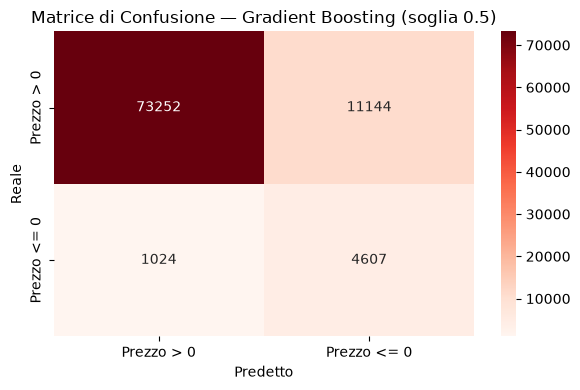


3. Calcolo permutation importance (campione 20k righe)...


/var/folders/cq/1g6r7fvn2v17_75jqzn2479c0000gn/T/ipykernel_60102/4236593676.py:113: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importanza.values, y=importanza.index, palette="viridis")


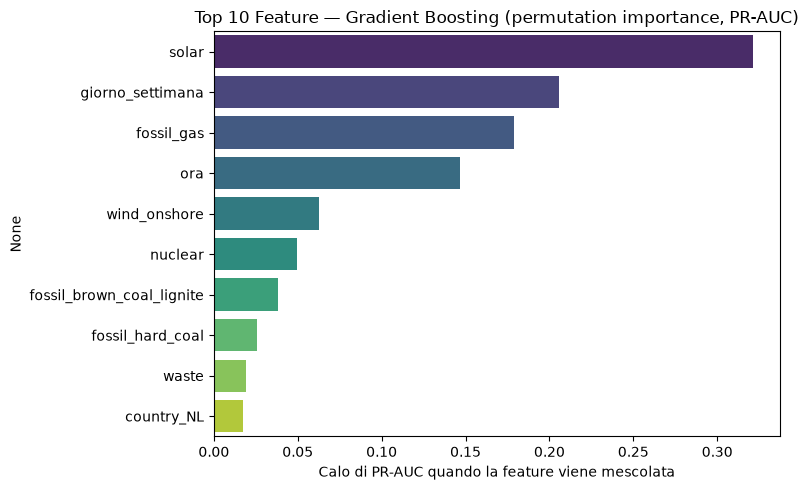


=== Riepilogo ===
                   accuracy  precision  recall      f1  roc_auc  pr_auc
KNN (k=5)            0.9491     0.6541  0.3950  0.4925   0.8266  0.4378
Decision Tree        0.9236     0.4239  0.6152  0.5020   0.7856  0.2923
Naive Bayes          0.9223     0.3731  0.3561  0.3644   0.8444  0.3210
Gradient Boosting    0.8648     0.2925  0.8181  0.4309   0.9256  0.5473

✅ File salvati in: /Users/antonio/Desktop/Classificazione/output/gradient_boosting


In [10]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
)
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import time

# ── Helper + accumulatori (idempotenti) ──
try:
    risultati
except NameError:
    risultati = {}
try:
    y_proba_dict
except NameError:
    y_proba_dict = {}


def valuta_modello(nome, modello, X_te, y_te, soglia=0.5):
    y_proba = modello.predict_proba(X_te)[:, 1]
    y_pred  = (y_proba >= soglia).astype(int)
    met = {
        "accuracy":  accuracy_score(y_te, y_pred),
        "precision": precision_score(y_te, y_pred, zero_division=0),
        "recall":    recall_score(y_te, y_pred, zero_division=0),
        "f1":        f1_score(y_te, y_pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_te, y_proba),
        "pr_auc":    average_precision_score(y_te, y_proba),
    }
    risultati[nome]    = met
    y_proba_dict[nome] = y_proba
    print(f"\n=== {nome} (soglia {soglia}) ===")
    print(classification_report(y_te, y_pred, target_names=["Prezzo > 0", "Prezzo <= 0"]))
    print({k: round(v, 4) for k, v in met.items()})
    return y_pred


# ── Cartella di output ──
out_dir = Path("output/gradient_boosting")
out_dir.mkdir(parents=True, exist_ok=True)

# ══════════════════════════════════════════════════════════════
# 1. Sample weights per bilanciare lo sbilanciamento (94/6)
#    Equivalente a class_weight="balanced" ma per GB di sklearn
# ══════════════════════════════════════════════════════════════
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
w_pos = n_neg / n_pos
sample_weights = np.where(y_train == 1, w_pos, 1.0)

print(f"Sbilanciamento: {n_neg} negativi / {n_pos} positivi → peso classe 1 = {w_pos:.2f}")

# ══════════════════════════════════════════════════════════════
# 2. Gradient Boosting
# ══════════════════════════════════════════════════════════════
print("\n2. Addestramento Gradient Boosting (potrebbe richiedere 2-5 minuti)...")
t0 = time.time()
gb = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
)
gb.fit(X_train, y_train, sample_weight=sample_weights)
print(f"   Fit completato in {time.time() - t0:.0f}s")

y_pred_gb = valuta_modello("Gradient Boosting", gb, X_test, y_test)

# ── Salvataggio report testuale ──
report_str = classification_report(
    y_test, y_pred_gb, target_names=["Prezzo > 0", "Prezzo <= 0"]
)
(out_dir / "classification_report_t1.txt").write_text(report_str, encoding="utf-8")

# ── Matrice di confusione ──
plt.figure(figsize=(6, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_gb),
    annot=True, fmt="d", cmap="Reds",
    xticklabels=["Prezzo > 0", "Prezzo <= 0"],
    yticklabels=["Prezzo > 0", "Prezzo <= 0"],
)
plt.title("Matrice di Confusione — Gradient Boosting (soglia 0.5)")
plt.ylabel("Reale")
plt.xlabel("Predetto")
plt.tight_layout()
plt.savefig(out_dir / "matrice_confusione_gb_t1.png", dpi=300)
plt.show()

# ══════════════════════════════════════════════════════════════
# 3. Feature importance (permutazione — più robusta di quella di Gini)
# ══════════════════════════════════════════════════════════════
from sklearn.inspection import permutation_importance

print("\n3. Calcolo permutation importance (campione 20k righe)...")
rng = np.random.RandomState(42)
idx_camp = rng.choice(len(X_test), size=min(20000, len(X_test)), replace=False)
pi = permutation_importance(
    gb, X_test.iloc[idx_camp], y_test.iloc[idx_camp],
    scoring="average_precision", n_repeats=3, random_state=42, n_jobs=-1,
)
importanza = (
    pd.Series(pi.importances_mean, index=X_train.columns)
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=importanza.values, y=importanza.index, palette="viridis")
plt.title("Top 10 Feature — Gradient Boosting (permutation importance, PR-AUC)")
plt.xlabel("Calo di PR-AUC quando la feature viene mescolata")
plt.tight_layout()
plt.savefig(out_dir / "feature_importance_gb_t1.png", dpi=300)
plt.show()

# ══════════════════════════════════════════════════════════════
# 4. Riepilogo
# ══════════════════════════════════════════════════════════════
print("\n=== Riepilogo ===")
print(pd.DataFrame(risultati).T.round(4).to_string())
print(f"\n✅ File salvati in: {out_dir.resolve()}")

Train interno: 154615 | Validation: 38654
Target=1 → train interno: 4.24% | validation: 4.24%

Soglia ottimale (F1 max su validation): 0.820
F1 sul validation a quella soglia: 0.5463

=== Gradient Boosting (soglia ottimale 0.820) ===
              precision    recall  f1-score   support

  Prezzo > 0       0.97      0.98      0.97     84396
 Prezzo <= 0       0.58      0.51      0.54      5631

    accuracy                           0.95     90027
   macro avg       0.77      0.74      0.76     90027
weighted avg       0.94      0.95      0.94     90027

{'accuracy': 0.9459, 'precision': 0.5772, 'recall': 0.5079, 'f1': 0.5403, 'roc_auc': 0.9256, 'pr_auc': 0.5473}


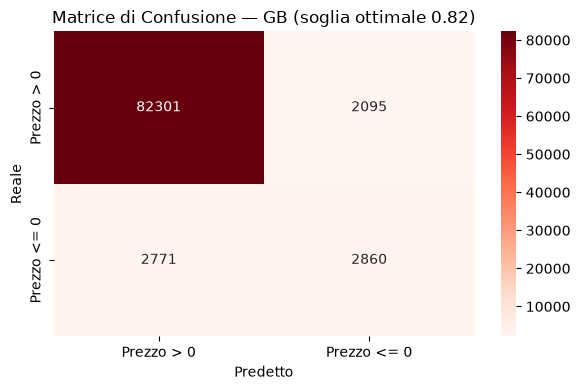


=== Confronto GB: soglia 0.5 vs soglia ottimale ===
           soglia 0.5  soglia 0.82
accuracy       0.8648       0.9459
precision      0.2925       0.5772
recall         0.8181       0.5079
f1             0.4309       0.5403
roc_auc        0.9256       0.9256
pr_auc         0.5473       0.5473

=== Riepilogo di tutti i modelli ===
                                 accuracy  precision  recall      f1  roc_auc  pr_auc
KNN (k=5)                          0.9491     0.6541  0.3950  0.4925   0.8266  0.4378
Decision Tree                      0.9236     0.4239  0.6152  0.5020   0.7856  0.2923
Naive Bayes                        0.9223     0.3731  0.3561  0.3644   0.8444  0.3210
Gradient Boosting                  0.8648     0.2925  0.8181  0.4309   0.9256  0.5473
Gradient Boosting (soglia 0.82)    0.9459     0.5772  0.5079  0.5403   0.9256  0.5473


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve

# ══════════════════════════════════════════════════════════════
# 1. Split interno al train per trovare la soglia ottimale
#    (MAI sul test: sarebbe leakage!)
# ══════════════════════════════════════════════════════════════
X_tr2, X_val, y_tr2, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

print(f"Train interno: {len(X_tr2)} | Validation: {len(X_val)}")
print(f"Target=1 → train interno: {y_tr2.mean():.2%} | validation: {y_val.mean():.2%}")

# Riaddestra GB sul train interno (senza toccare X_test)
w_tr2 = np.where(y_tr2 == 1, (y_tr2 == 0).sum() / (y_tr2 == 1).sum(), 1.0)
gb_val = GradientBoostingClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42
)
gb_val.fit(X_tr2, y_tr2, sample_weight=w_tr2)

# Cerca la soglia che massimizza F1 sul validation
p_val = gb_val.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1_scores = 2 * prec * rec / (prec + rec + 1e-12)
idx_best = np.argmax(f1_scores[:-1])
soglia_ottimale = float(thr[idx_best])

print(f"\nSoglia ottimale (F1 max su validation): {soglia_ottimale:.3f}")
print(f"F1 sul validation a quella soglia: {f1_scores[idx_best]:.4f}")

# ══════════════════════════════════════════════════════════════
# 2. Rivaluta il GB già addestrato (gb) sul TEST con la soglia ottimale
# ══════════════════════════════════════════════════════════════
y_proba_gb = gb.predict_proba(X_test)[:, 1]
y_pred_gb_opt = (y_proba_gb >= soglia_ottimale).astype(int)

met_opt = {
    "accuracy":  accuracy_score(y_test, y_pred_gb_opt),
    "precision": precision_score(y_test, y_pred_gb_opt, zero_division=0),
    "recall":    recall_score(y_test, y_pred_gb_opt, zero_division=0),
    "f1":        f1_score(y_test, y_pred_gb_opt, zero_division=0),
    "roc_auc":   roc_auc_score(y_test, y_proba_gb),
    "pr_auc":    average_precision_score(y_test, y_proba_gb),
}
risultati[f"Gradient Boosting (soglia {soglia_ottimale:.2f})"] = met_opt
y_proba_dict[f"Gradient Boosting (soglia {soglia_ottimale:.2f})"] = y_proba_gb

print(f"\n=== Gradient Boosting (soglia ottimale {soglia_ottimale:.3f}) ===")
print(classification_report(
    y_test, y_pred_gb_opt, target_names=["Prezzo > 0", "Prezzo <= 0"]
))
print({k: round(v, 4) for k, v in met_opt.items()})

# ── Matrice di confusione ──
plt.figure(figsize=(6, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_gb_opt),
    annot=True, fmt="d", cmap="Reds",
    xticklabels=["Prezzo > 0", "Prezzo <= 0"],
    yticklabels=["Prezzo > 0", "Prezzo <= 0"],
)
plt.title(f"Matrice di Confusione — GB (soglia ottimale {soglia_ottimale:.2f})")
plt.ylabel("Reale")
plt.xlabel("Predetto")
plt.tight_layout()
plt.savefig(out_dir / f"matrice_confusione_gb_soglia_{soglia_ottimale:.2f}.png", dpi=300)
plt.show()

# ══════════════════════════════════════════════════════════════
# 3. Confronto: GB soglia 0.5 vs GB soglia ottimale
# ══════════════════════════════════════════════════════════════
print("\n=== Confronto GB: soglia 0.5 vs soglia ottimale ===")
confronto = pd.DataFrame({
    "soglia 0.5":            risultati["Gradient Boosting"],
    f"soglia {soglia_ottimale:.2f}": met_opt,
}).round(4)
print(confronto.to_string())

# ══════════════════════════════════════════════════════════════
# 4. Riepilogo finale
# ══════════════════════════════════════════════════════════════
print("\n=== Riepilogo di tutti i modelli ===")
print(pd.DataFrame(risultati).T.round(4).to_string())